# Predicting Axial Bearing Capacity of Precast Concrete Driven Piles
## Using ANN, GA Regression, and GA-ANN Hybrid Models
> **Compatible with:** Google Colab (Python 3.x)  
> **Dataset:** `Data_set_artikel.xlsx`  (sheets: Training / Testing / Validation)

In [ ]:
# Install required packages (run once in Colab)
!pip install deap openpyxl joblib --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.1/93.1 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 866.9/866.9 kB 16.7 MB/s eta 0:00:00


In [ ]:
# ── PART 1 — Imports & Reproducibility ──────────────────────────────────
import os, random, warnings
warnings.filterwarnings('ignore')

os.environ['PYTHONHASHSEED']       = '0'
os.environ['TF_DETERMINISTIC_OPS'] = '1'

random.seed(42)

import numpy as np
np.random.seed(42)

import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import tensorflow as tf
tf.random.set_seed(42)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from deap import base, creator, tools

print('✅ Libraries imported')
print(f'   TensorFlow : {tf.__version__}')
print(f'   NumPy      : {np.__version__}')

✅ Libraries imported
   TensorFlow : 2.20.0
   NumPy      : 2.0.2


In [ ]:
# ── GLOBAL CONFIGURATION — modify here as needed ─────────────────────────

# ── Dataset ──
EXCEL_FILE_PATH  = 'Data set artikel.xlsx'   # upload this file to Colab first
SHEET_TRAIN      = 'Training'
SHEET_TEST       = 'Testing'
SHEET_VALIDATION = 'Validation'

INPUT_COLUMNS  = ['Input 1', 'Input 2', 'Input 3', 'Input 4', 'Input 5']
OUTPUT_COLUMN  = 'Target 1'

# ── ANN hyperparameters ──
ANN_HIDDEN_LAYERS = 2
ANN_NEURONS       = 64
ANN_ACTIVATION    = 'relu'
ANN_LEARNING_RATE = 0.001
ANN_EPOCHS        = 1000
ANN_BATCH_SIZE    = 32
ANN_PATIENCE      = 20

# ── GA Regression hyperparameters ──
GA_POPULATION_SIZE = 100
GA_N_GENERATIONS   = 200
GA_CROSSOVER_PROB  = 0.7
GA_MUTATION_PROB   = 0.2
GA_TOURNAMENT_SIZE = 5
GA_RANDOM_SEED     = 42

# ── GA-ANN hyperparameters ──
GA_ANN_POPULATION   = 20
GA_ANN_GENERATIONS  = 30
GA_ANN_CROSSOVER    = 0.7
GA_ANN_MUTATION     = 0.3
GA_ANN_EPOCHS_CAND  = 50
GA_ANN_EPOCHS_FINAL = 500
GA_ANN_PATIENCE     = 20
GA_ANN_ACTIVATION   = 'relu'

# ── GA-ANN search space ──
NEURONS_L1_CHOICES = [16, 32, 64, 128]
NEURONS_L2_CHOICES = [0,  16, 32, 64]
LR_CHOICES         = [0.001, 0.005, 0.01, 0.05]
BATCH_CHOICES      = [16, 32, 64]

print('✅ Configuration set.')

✅ Configuration set.


In [ ]:
# ── Upload dataset (Colab only) ─────────────────────────────────────────
# Run this cell to upload Data_set_artikel.xlsx from your computer.
# Skip if the file is already in the Colab runtime (e.g. mounted Drive).

try:
    from google.colab import files
    uploaded = files.upload()   # select Data_set_artikel.xlsx
    print('✅ File uploaded:', list(uploaded.keys()))
except ImportError:
    print('ℹ️  Not running in Colab — make sure the file is in the working directory.')

Saving Data set artikel.xlsx to Data set artikel.xlsx
✅ File uploaded: ['Data set artikel.xlsx']


In [ ]:
# ── PART 2 — Load Dataset ───────────────────────────────────────────────

def load_sheet(path, sheet):
    df = pd.read_excel(path, sheet_name=sheet)
    df = df.dropna(subset=[INPUT_COLUMNS[0]])   # drop empty/header rows
    df = df[INPUT_COLUMNS + [OUTPUT_COLUMN]].reset_index(drop=True)
    return df

df_train = load_sheet('Data set artikel.xlsx', 'Training')
df_test  = load_sheet('Data set artikel.xlsx', 'Testing')
df_val   = load_sheet('Data set artikel.xlsx', 'Validation')

X_train = df_train[INPUT_COLUMNS].values
y_train = df_train[OUTPUT_COLUMN].values.reshape(-1, 1)

X_test  = df_test[INPUT_COLUMNS].values
y_test  = df_test[OUTPUT_COLUMN].values.reshape(-1, 1)

X_val   = df_val[INPUT_COLUMNS].values
y_val   = df_val[OUTPUT_COLUMN].values.reshape(-1, 1)

print(f'Training   : X={X_train.shape}, y={y_train.shape}')
print(f'Testing    : X={X_test.shape},  y={y_test.shape}')
print(f'Validation : X={X_val.shape},   y={y_val.shape}')
df_train.head()

Training   : X=(125, 5), y=(125, 1)
Testing    : X=(43, 5),  y=(43, 1)
Validation : X=(41, 5),   y=(41, 1)


,Input 1,Input 2,Input 3,Input 4,Input 5,Target 1
0,225.73,17.0,2.5,0.4,0.8,78.0
1,225.73,16.5,2.5,0.4,0.7,77.0
2,225.73,17.0,2.5,0.4,0.7,74.0
3,225.73,17.0,2.5,0.4,0.6,78.0
4,225.73,17.0,2.5,0.4,0.7,77.0


In [ ]:
# ── PART 3 — Data Normalisation ────────────────────────────────────────

scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_s = scaler_X.fit_transform(X_train)
y_train_s = scaler_y.fit_transform(y_train)

X_test_s  = scaler_X.transform(X_test)
y_test_s  = scaler_y.transform(y_test)

X_val_s   = scaler_X.transform(X_val)
y_val_s   = scaler_y.transform(y_val)

joblib.dump(scaler_X, 'scaler_X.pkl')
joblib.dump(scaler_y, 'scaler_y.pkl')

y_true_train = y_train.flatten()
y_true_test  = y_test.flatten()
y_true_val   = y_val.flatten()

def inv_y(y_s):
    return scaler_y.inverse_transform(np.array(y_s).reshape(-1,1)).flatten()

print('✅ Normalisation complete. Scalers fitted on training data only.')

✅ Normalisation complete. Scalers fitted on training data only.


In [ ]:
# ── Helper — Metrics & Table ────────────────────────────────────────────

def compute_metrics(y_true, y_pred, eps=1e-8):
    y_true, y_pred = np.array(y_true).flatten(), np.array(y_pred).flatten()
    return {
        'R':        round(float(np.corrcoef(y_true, y_pred)[0, 1]), 4),
        'R²':       round(float(r2_score(y_true, y_pred)), 4),
        'RMSE':     round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 4),
        'MAE':      round(float(mean_absolute_error(y_true, y_pred)), 4),
        'MAPE (%)': round(float(np.mean(np.abs((y_true-y_pred)/(np.abs(y_true)+eps)))*100), 4),
    }

def metrics_table(results, model_name):
    df = pd.DataFrame([
        {'Dataset': split, **metrics}
        for split, metrics in results.items()
    ]).set_index('Dataset')
    print(f'\n{'─'*50}')
    print(f'  {model_name} — Performance Metrics')
    print(f'{'─'*50}')
    print(df.to_string())
    return df

print('✅ Helper functions ready.')

✅ Helper functions ready.


In [ ]:
# ── PART 4 — ANN Model ──────────────────────────────────────────────────

def build_ann(n_in, n_hidden, neurons, activation, lr):
    m = Sequential()
    m.add(Dense(neurons, activation=activation, input_shape=(n_in,)))
    for _ in range(n_hidden - 1):
        m.add(Dense(neurons, activation=activation))
    m.add(Dense(1))
    m.compile(optimizer=Adam(lr), loss='mse')
    return m

n_inputs = X_train_s.shape[1]

tf.random.set_seed(42)
ann_model = build_ann(n_inputs, ANN_HIDDEN_LAYERS, ANN_NEURONS,
                      ANN_ACTIVATION, ANN_LEARNING_RATE)
ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,609 (18.00 KB)

 Trainable params: 4,609 (18.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ── DATA CHECKING & CLEANING ───────────────────────────────────────────────

def clean_dataset(df, sheet_name):
    print(f"\n===== Checking Sheet: {sheet_name} =====")

    # Ambil kolom yang diperlukan
    df = df[INPUT_COLUMNS + [OUTPUT_COLUMN]].copy()

    # Ubah semua kolom menjadi numeric
    for col in INPUT_COLUMNS + [OUTPUT_COLUMN]:
        df[col] = pd.to_numeric(df[col], errors='coerce')

    # Cek missing value
    print("\nMissing values before cleaning:")
    print(df.isna().sum())

    # Drop baris yang punya NaN pada input/output
    df = df.dropna(subset=INPUT_COLUMNS + [OUTPUT_COLUMN])

    # Drop duplicate rows
    before_dup = len(df)
    df = df.drop_duplicates()
    after_dup = len(df)
    print(f"\nDuplicate rows removed: {before_dup - after_dup}")

    # Cek statistik dasar
    print("\nDescriptive statistics:")
    print(df.describe())

    # Reset index
    df = df.reset_index(drop=True)

    print(f"\nFinal shape after cleaning: {df.shape}")
    return df


df_train = pd.read_excel('Data set artikel.xlsx', sheet_name= 'Training')
df_test  = pd.read_excel('Data set artikel.xlsx', sheet_name= 'Testing')
df_val   = pd.read_excel('Data set artikel.xlsx', sheet_name= 'Validation')

df_train = clean_dataset(df_train, "Training")
df_test  = clean_dataset(df_test, "Testing")
df_val   = clean_dataset(df_val, "Validation")

X_train = df_train[INPUT_COLUMNS].values
y_train = df_train[OUTPUT_COLUMN].values.reshape(-1, 1)

X_test  = df_test[INPUT_COLUMNS].values
y_test  = df_test[OUTPUT_COLUMN].values.reshape(-1, 1)

X_val   = df_val[INPUT_COLUMNS].values
y_val   = df_val[OUTPUT_COLUMN].values.reshape(-1, 1)

print(f'\nTraining   : X={X_train.shape}, y={y_train.shape}')
print(f'Testing    : X={X_test.shape},  y={y_test.shape}')
print(f'Validation : X={X_val.shape},   y={y_val.shape}')


===== Checking Sheet: Training =====

Missing values before cleaning:
Input 1     1
Input 2     1
Input 3     1
Input 4     1
Input 5     1
Target 1    1
dtype: int64

Duplicate rows removed: 4

Descriptive statistics:
          Input 1     Input 2     Input 3     Input 4     Input 5    Target 1
count  121.000000  121.000000  121.000000  121.000000  121.000000  121.000000
mean   278.875455   19.920248    3.566942    0.757686    1.234132  126.055372
std     28.882937   10.610265    2.731709    0.353253    0.827645   80.122315
min    225.730000    3.300000    1.200000    0.200000    0.220000   29.100000
25%    282.170000   10.500000    1.300000    0.600000    0.590000   64.200000
50%    282.170000   20.100000    2.500000    1.000000    0.970000   94.900000
75%    300.000000   27.000000    5.000000    1.000000    1.850000  173.000000
max    306.020000   48.000000    9.000000    3.000000    3.500000  298.000000

Final shape after cleaning: (121, 6)

===== Checking Sheet: Testing =====

Mi

In [ ]:
print("Scaled X_train range:")
print(pd.DataFrame(X_train_s, columns=INPUT_COLUMNS).describe())

print("\nScaled X_test range:")
print(pd.DataFrame(X_test_s, columns=INPUT_COLUMNS).describe())

print("\nScaled X_val range:")
print(pd.DataFrame(X_val_s, columns=INPUT_COLUMNS).describe())

Scaled X_train range:
          Input 1     Input 2     Input 3     Input 4     Input 5
count  125.000000  125.000000  125.000000  125.000000  125.000000
mean     0.671538    0.380447    0.317538    0.193943    0.310561
std      0.357910    0.246874    0.356184    0.127427    0.250339
min      0.000000    0.000000    0.000000    0.000000    0.000000
25%      0.702952    0.172260    0.012821    0.107143    0.115854
50%      0.702952    0.375839    0.166667    0.178571    0.228659
75%      0.925022    0.530201    0.487179    0.285714    0.512195
max      1.000000    1.000000    1.000000    1.000000    1.000000

Scaled X_test range:
         Input 1    Input 2    Input 3    Input 4    Input 5
count  43.000000  43.000000  43.000000  43.000000  43.000000
mean    3.047966   0.385984   0.648181   0.218854   0.670732
std     0.743224   0.170078   0.298372   0.180815   0.783424
min     2.170507   0.116331   0.012821   0.035714   0.009146
25%     2.802404   0.241611   0.423077   0.071429   0.419

In [ ]:
from sklearn.model_selection import train_test_split

# Gabungkan semua sheet
df_all = pd.concat([df_train, df_test, df_val], axis=0).reset_index(drop=True)

# Shuffle data
df_all = df_all.sample(frac=1, random_state=42).reset_index(drop=True)

X_all = df_all[INPUT_COLUMNS].values
y_all = df_all[OUTPUT_COLUMN].values.reshape(-1, 1)

# Split: 70% train, 15% test, 15% validation
X_train, X_temp, y_train, y_temp = train_test_split(
    X_all, y_all,
    test_size=0.30,
    random_state=42
)

X_test, X_val, y_test, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)

print(f"Training   : X={X_train.shape}, y={y_train.shape}")
print(f"Testing    : X={X_test.shape},  y={y_test.shape}")
print(f"Validation : X={X_val.shape},   y={y_val.shape}")

Training   : X=(142, 5), y=(142, 1)
Testing    : X=(30, 5),  y=(30, 1)
Validation : X=(31, 5),   y=(31, 1)


In [ ]:
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_s = scaler_X.fit_transform(X_train)
y_train_s = scaler_y.fit_transform(y_train)

X_test_s = scaler_X.transform(X_test)
y_test_s = scaler_y.transform(y_test)

X_val_s = scaler_X.transform(X_val)
y_val_s = scaler_y.transform(y_val)

In [ ]:
# Update true values after cleaning / resplitting
y_true_train = y_train.flatten()
y_true_test  = y_test.flatten()
y_true_val   = y_val.flatten()

print("Check data length:")
print("y_true_train:", len(y_true_train))
print("y_true_test :", len(y_true_test))
print("y_true_val  :", len(y_true_val))

Check data length:
y_true_train: 142
y_true_test : 30
y_true_val  : 31


In [ ]:
# ── Train ANN ──────────────────────────────────────────────────────────

ANN_HIDDEN_LAYERS = 2
ANN_NEURONS       = 64
ANN_LEARNING_RATE = 0.001
ANN_EPOCHS        = 300
ANN_BATCH_SIZE    = 8
ANN_PATIENCE      = 20

es_ann = EarlyStopping(monitor='val_loss', patience=ANN_PATIENCE,
                       restore_best_weights=True, verbose=0)

ann_history = ann_model.fit(
    X_train_s, y_train_s,
    epochs=ANN_EPOCHS, batch_size=ANN_BATCH_SIZE,
    validation_data=(X_val_s, y_val_s),
    callbacks=[es_ann], verbose=1
)

y_pred_train_ANN = inv_y(ann_model.predict(X_train_s))
y_pred_test_ANN  = inv_y(ann_model.predict(X_test_s))
y_pred_val_ANN   = inv_y(ann_model.predict(X_val_s))

ann_results = {
    'Training':   compute_metrics(y_true_train, y_pred_train_ANN),
    'Testing':    compute_metrics(y_true_test,  y_pred_test_ANN),
    'Validation': compute_metrics(y_true_val,   y_pred_val_ANN),
}
df_ann = metrics_table(ann_results, 'ANN')

Epoch 1/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0804 - val_loss: 0.0371
Epoch 2/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0280 - val_loss: 0.0264
Epoch 3/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0189 - val_loss: 0.0212
Epoch 4/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0144 - val_loss: 0.0183
Epoch 5/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0131 - val_loss: 0.0172
Epoch 6/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0122 - val_loss: 0.0161
Epoch 7/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0116 - val_loss: 0.0156
Epoch 8/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0112 - val_loss: 0.0151
Epoch 9/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0108 - val_loss: 0.0146
Epoch 10/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0105 - val_loss: 0.0143
Epoch 11/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0103 - val_loss: 0.0140
Epoch 12/300
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 

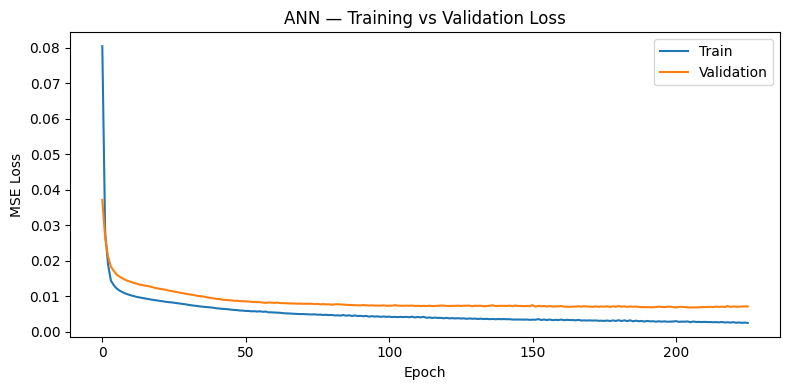

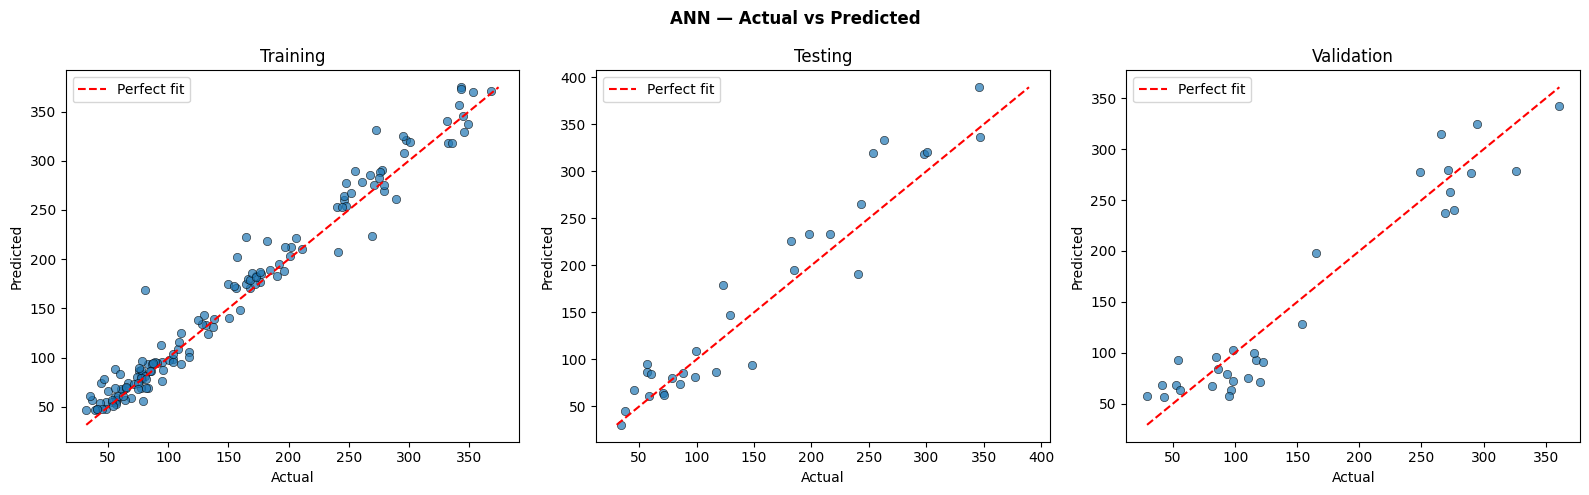

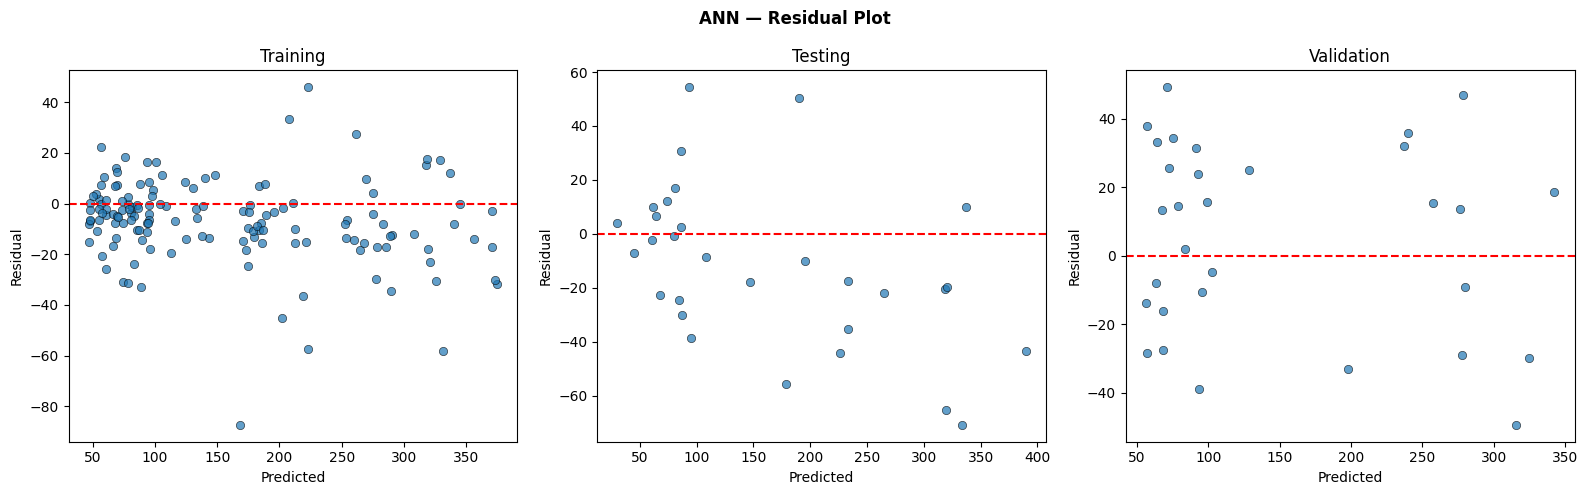

In [ ]:
# ── ANN — Plots ────────────────────────────────────────────────────────

# Loss curve
plt.figure(figsize=(8,4))
plt.plot(ann_history.history['loss'],     label='Train')
plt.plot(ann_history.history['val_loss'], label='Validation')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.title('ANN — Training vs Validation Loss'); plt.legend()
plt.tight_layout(); plt.savefig('ANN_loss_curve.png', dpi=150); plt.show()

# Actual vs Predicted
fig, axes = plt.subplots(1, 3, figsize=(16,5))
fig.suptitle('ANN — Actual vs Predicted', fontweight='bold')
for ax, (yt, yp, ttl) in zip(axes, [
        (y_true_train, y_pred_train_ANN, 'Training'),
        (y_true_test,  y_pred_test_ANN,  'Testing'),
        (y_true_val,   y_pred_val_ANN,   'Validation')]):
    ax.scatter(yt, yp, alpha=0.7, edgecolors='k', lw=0.5)
    lo, hi = min(yt.min(), yp.min()), max(yt.max(), yp.max())
    ax.plot([lo,hi],[lo,hi],'r--',lw=1.5,label='Perfect fit')
    ax.set_title(ttl); ax.set_xlabel('Actual'); ax.set_ylabel('Predicted'); ax.legend()
plt.tight_layout(); plt.savefig('ANN_actual_vs_predicted.png', dpi=150); plt.show()

# Residuals
fig, axes = plt.subplots(1, 3, figsize=(16,5))
fig.suptitle('ANN — Residual Plot', fontweight='bold')
for ax, (yt, yp, ttl) in zip(axes, [
        (y_true_train, y_pred_train_ANN, 'Training'),
        (y_true_test,  y_pred_test_ANN,  'Testing'),
        (y_true_val,   y_pred_val_ANN,   'Validation')]):
    ax.scatter(yp, yt-yp, alpha=0.7, edgecolors='k', lw=0.5)
    ax.axhline(0, color='r', ls='--', lw=1.5)
    ax.set_title(ttl); ax.set_xlabel('Predicted'); ax.set_ylabel('Residual')
plt.tight_layout(); plt.savefig('ANN_residuals.png', dpi=150); plt.show()

In [ ]:
# ── PART 5 — GA Regression Model ───────────────────────────────────────

random.seed(GA_RANDOM_SEED); np.random.seed(GA_RANDOM_SEED)
N_FEAT = X_train_s.shape[1]

# Safely re-create DEAP classes
for cls in ['FitnessMinGA', 'IndividualGA']:
    if hasattr(creator, cls): delattr(creator, cls)

creator.create('FitnessMinGA', base.Fitness, weights=(-1.0,))
creator.create('IndividualGA', list, fitness=creator.FitnessMinGA)

tb_ga = base.Toolbox()
tb_ga.register('attr_float', random.uniform, -5.0, 5.0)
tb_ga.register('individual', tools.initRepeat, creator.IndividualGA,
               tb_ga.attr_float, n=N_FEAT + 1)
tb_ga.register('population', tools.initRepeat, list, tb_ga.individual)

def ga_pred(chrom, X):
    return X @ np.array(chrom[:N_FEAT]) + chrom[N_FEAT]

def ga_fit(chrom):
    yp = ga_pred(chrom, X_train_s)
    return (float(np.sqrt(np.mean((y_train_s.flatten() - yp)**2))),)

tb_ga.register('evaluate', ga_fit)
tb_ga.register('mate',     tools.cxBlend, alpha=0.5)
tb_ga.register('mutate',   tools.mutGaussian, mu=0, sigma=0.5, indpb=0.2)
tb_ga.register('select',   tools.selTournament, tournsize=GA_TOURNAMENT_SIZE)

pop_ga = tb_ga.population(n=GA_POPULATION_SIZE)
ga_best_per_gen = []

print(f'Running GA: {GA_N_GENERATIONS} gen × {GA_POPULATION_SIZE} individuals …')
for gen in range(GA_N_GENERATIONS):
    offspring = list(map(tb_ga.clone, tb_ga.select(pop_ga, len(pop_ga))))
    for c1, c2 in zip(offspring[::2], offspring[1::2]):
        if random.random() < GA_CROSSOVER_PROB:
            tb_ga.mate(c1, c2)
            del c1.fitness.values, c2.fitness.values
    for mut in offspring:
        if random.random() < GA_MUTATION_PROB:
            tb_ga.mutate(mut); del mut.fitness.values
    for ind in [i for i in offspring if not i.fitness.valid]:
        ind.fitness.values = tb_ga.evaluate(ind)
    pop_ga[:] = offspring
    best = min(i.fitness.values[0] for i in pop_ga)
    ga_best_per_gen.append(best)
    if (gen+1) % 50 == 0:
        print(f'  Gen {gen+1:>4d} | Best RMSE (scaled): {best:.6f}')

best_ga = tools.selBest(pop_ga, k=1)[0]
print(f'\nBest chromosome: {[round(v,4) for v in best_ga]}')

Running GA: 200 gen × 100 individuals …
  Gen   50 | Best RMSE (scaled): 0.128269
  Gen  100 | Best RMSE (scaled): 0.122916
  Gen  150 | Best RMSE (scaled): 0.115974
  Gen  200 | Best RMSE (scaled): 0.112566

Best chromosome: [0.1826, -0.1203, 0.7212, 0.3076, 0.4959, -0.0318]


In [ ]:
# ── GA — Predict & Metrics ─────────────────────────────────────────────

y_pred_train_GA = inv_y(ga_pred(best_ga, X_train_s))
y_pred_test_GA  = inv_y(ga_pred(best_ga, X_test_s))
y_pred_val_GA   = inv_y(ga_pred(best_ga, X_val_s))

ga_results = {
    'Training':   compute_metrics(y_true_train, y_pred_train_GA),
    'Testing':    compute_metrics(y_true_test,  y_pred_test_GA),
    'Validation': compute_metrics(y_true_val,   y_pred_val_GA),
}
df_ga = metrics_table(ga_results, 'GA Regression')


──────────────────────────────────────────────────
  GA Regression — Performance Metrics
──────────────────────────────────────────────────
                 R      R²     RMSE      MAE  MAPE (%)
Dataset                                               
Training    0.9173  0.8379  37.8446  27.4399   23.4540
Testing     0.9090  0.8147  41.1835  35.5335   40.9089
Validation  0.9006  0.8047  43.3025  36.9897   36.3167


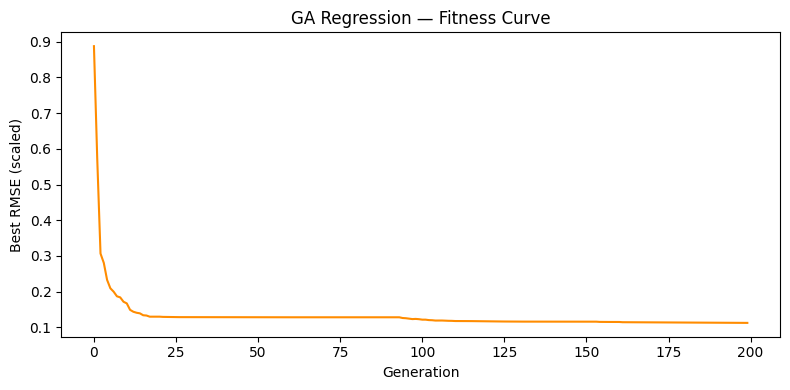

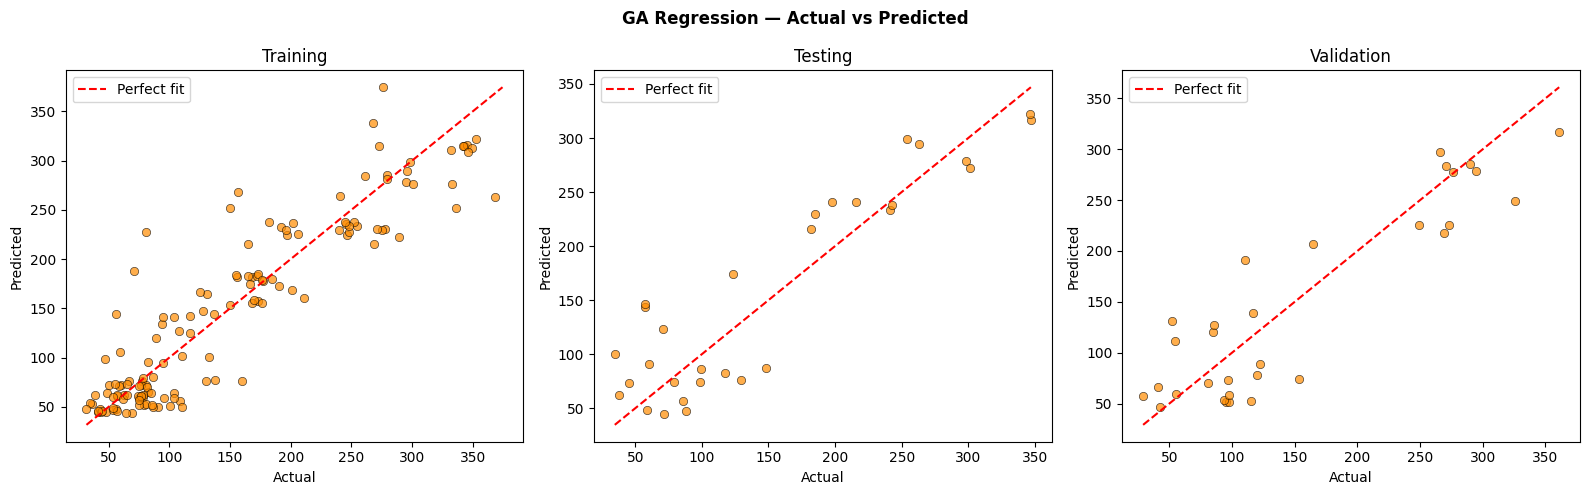

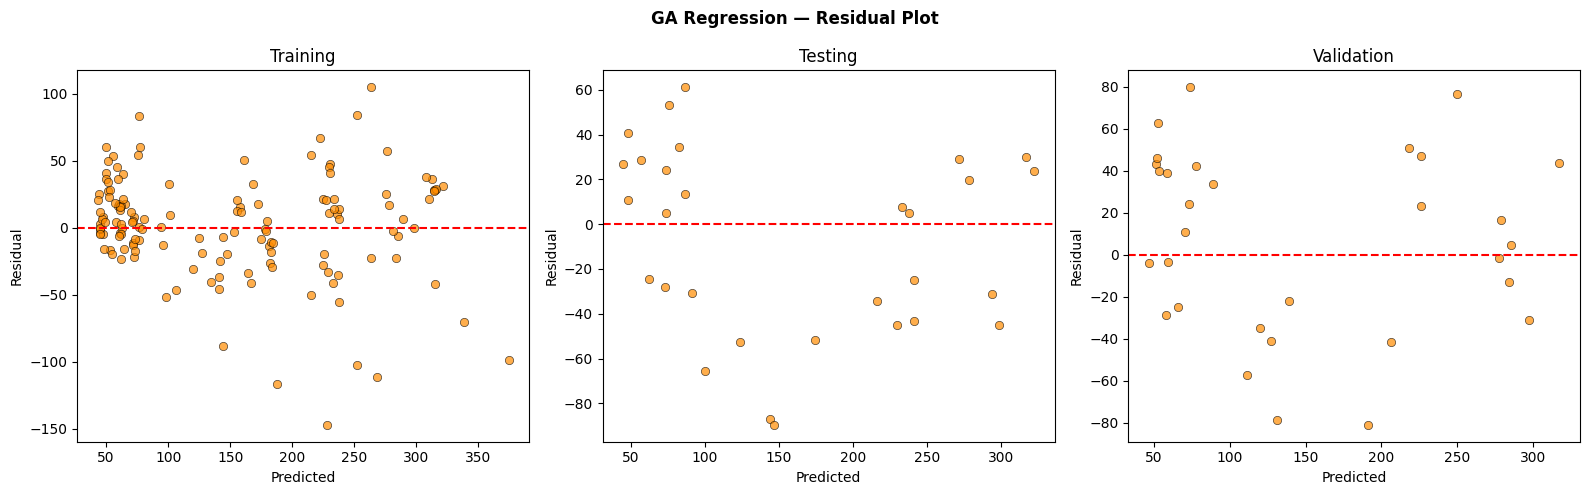

In [ ]:
# ── GA — Plots ─────────────────────────────────────────────────────────

plt.figure(figsize=(8,4))
plt.plot(ga_best_per_gen, color='darkorange')
plt.xlabel('Generation'); plt.ylabel('Best RMSE (scaled)')
plt.title('GA Regression — Fitness Curve')
plt.tight_layout(); plt.savefig('GA_fitness_curve.png', dpi=150); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16,5))
fig.suptitle('GA Regression — Actual vs Predicted', fontweight='bold')
for ax, (yt, yp, ttl) in zip(axes, [
        (y_true_train, y_pred_train_GA, 'Training'),
        (y_true_test,  y_pred_test_GA,  'Testing'),
        (y_true_val,   y_pred_val_GA,   'Validation')]):
    ax.scatter(yt, yp, alpha=0.7, edgecolors='k', lw=0.5, color='darkorange')
    lo, hi = min(yt.min(), yp.min()), max(yt.max(), yp.max())
    ax.plot([lo,hi],[lo,hi],'r--',lw=1.5,label='Perfect fit')
    ax.set_title(ttl); ax.set_xlabel('Actual'); ax.set_ylabel('Predicted'); ax.legend()
plt.tight_layout(); plt.savefig('GA_actual_vs_predicted.png', dpi=150); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16,5))
fig.suptitle('GA Regression — Residual Plot', fontweight='bold')
for ax, (yt, yp, ttl) in zip(axes, [
        (y_true_train, y_pred_train_GA, 'Training'),
        (y_true_test,  y_pred_test_GA,  'Testing'),
        (y_true_val,   y_pred_val_GA,   'Validation')]):
    ax.scatter(yp, yt-yp, alpha=0.7, edgecolors='k', lw=0.5, color='darkorange')
    ax.axhline(0, color='r', ls='--', lw=1.5)
    ax.set_title(ttl); ax.set_xlabel('Predicted'); ax.set_ylabel('Residual')
plt.tight_layout(); plt.savefig('GA_residuals.png', dpi=150); plt.show()

In [ ]:
# ── PART 6 — GA-ANN Hybrid Model ───────────────────────────────────────

CHROM_BOUNDS = [
    (0, len(NEURONS_L1_CHOICES)-1),
    (0, len(NEURONS_L2_CHOICES)-1),
    (0, len(LR_CHOICES)-1),
    (0, len(BATCH_CHOICES)-1),
]

def decode(chrom):
    idx = [int(round(max(lo, min(hi, g)))) for g,(lo,hi) in zip(chrom,CHROM_BOUNDS)]
    return (NEURONS_L1_CHOICES[idx[0]], NEURONS_L2_CHOICES[idx[1]],
            LR_CHOICES[idx[2]], BATCH_CHOICES[idx[3]])

def build_cand(n1, n2, lr, n_in):
    m = Sequential()
    m.add(Dense(n1, activation=GA_ANN_ACTIVATION, input_shape=(n_in,)))
    if n2 > 0: m.add(Dense(n2, activation=GA_ANN_ACTIVATION))
    m.add(Dense(1))
    m.compile(optimizer=Adam(lr), loss='mse')
    return m

def ga_ann_fitness(chrom):
    n1, n2, lr, batch = decode(chrom)
    tf.random.set_seed(42)
    m = build_cand(n1, n2, lr, n_inputs)
    es = EarlyStopping(monitor='val_loss', patience=10,
                       restore_best_weights=True, verbose=0)
    m.fit(X_train_s, y_train_s, epochs=GA_ANN_EPOCHS_CAND, batch_size=batch,
          validation_data=(X_val_s, y_val_s), callbacks=[es], verbose=0)
    yp = m.predict(X_val_s, verbose=0).flatten()
    return (float(np.sqrt(np.mean((y_val_s.flatten()-yp)**2))),)

random.seed(GA_RANDOM_SEED); np.random.seed(GA_RANDOM_SEED)
for cls in ['FitnessMinGAANN','IndividualGAANN']:
    if hasattr(creator, cls): delattr(creator, cls)

creator.create('FitnessMinGAANN', base.Fitness, weights=(-1.0,))
creator.create('IndividualGAANN', list, fitness=creator.FitnessMinGAANN)

tb2 = base.Toolbox()
tb2.register('individual', tools.initIterate, creator.IndividualGAANN,
             lambda: creator.IndividualGAANN(
                 [random.randint(lo,hi) for lo,hi in CHROM_BOUNDS]))
tb2.register('population', tools.initRepeat, list, tb2.individual)
tb2.register('evaluate',   ga_ann_fitness)
tb2.register('mate',       tools.cxUniform, indpb=0.5)
tb2.register('mutate',     tools.mutUniformInt,
             low=[lo for lo,hi in CHROM_BOUNDS],
             up=[hi for lo,hi in CHROM_BOUNDS], indpb=0.4)
tb2.register('select',     tools.selTournament, tournsize=3)

print('✅ GA-ANN setup complete.')

✅ GA-ANN setup complete.


In [ ]:
# ── GA-ANN Evolution ────────────────────────────────────────────────────

pop2 = tb2.population(n=GA_ANN_POPULATION)
ga_ann_best_per_gen = []

print(f'Running GA-ANN: {GA_ANN_GENERATIONS} gen × {GA_ANN_POPULATION} individuals …')
print(f'(Each candidate trains ≤{GA_ANN_EPOCHS_CAND} epochs — may take several minutes)')

for gen in range(GA_ANN_GENERATIONS):
    offspring = list(map(tb2.clone, tb2.select(pop2, len(pop2))))
    for c1, c2 in zip(offspring[::2], offspring[1::2]):
        if random.random() < GA_ANN_CROSSOVER:
            tb2.mate(c1, c2); del c1.fitness.values, c2.fitness.values
    for mut in offspring:
        if random.random() < GA_ANN_MUTATION:
            tb2.mutate(mut); del mut.fitness.values
    for ind in [i for i in offspring if not i.fitness.valid]:
        ind.fitness.values = tb2.evaluate(ind)
    pop2[:] = offspring
    best = min(i.fitness.values[0] for i in pop2)
    ga_ann_best_per_gen.append(best)
    print(f'  Gen {gen+1:>3d}/{GA_ANN_GENERATIONS} | Best Val RMSE (scaled): {best:.6f}')

best_ga_ann = tools.selBest(pop2, k=1)[0]
b_n1, b_n2, b_lr, b_batch = decode(best_ga_ann)
print(f'\n── Best GA-ANN Hyperparameters ──')
print(f'  Neurons L1    : {b_n1}')
print(f'  Neurons L2    : {b_n2} {"(disabled)" if b_n2==0 else ""}')
print(f'  Learning Rate : {b_lr}')
print(f'  Batch Size    : {b_batch}')

Running GA-ANN: 30 gen × 20 individuals …
(Each candidate trains ≤50 epochs — may take several minutes)


  Gen   1/30 | Best Val RMSE (scaled): 0.089834
  Gen   2/30 | Best Val RMSE (scaled): 0.089834
  Gen   3/30 | Best Val RMSE (scaled): 0.087214
  Gen   4/30 | Best Val RMSE (scaled): 0.087214
  Gen   5/30 | Best Val RMSE (scaled): 0.085025
  Gen   6/30 | Best Val RMSE (scaled): 0.084698
  Gen   7/30 | Best Val RMSE (scaled): 0.084698
  Gen   8/30 | Best Val RMSE (scaled): 0.086487
  Gen   9/30 | Best Val RMSE (scaled): 0.087346
  Gen  10/30 | Best Val RMSE (scaled): 0.087346
  Gen  11/30 | Best Val RMSE (scaled): 0.087290
  Gen  12/30 | Best Val RMSE (scaled): 0.087290
  Gen  13/30 | Best Val RMSE (scaled): 0.085346
  Gen  14/30 | Best Val RMSE (scaled): 0.085346
  Gen  15/30 | Best Val RMSE (scaled): 0.087657
  Gen  16/30 | Best Val RMSE (scaled): 0.087220
  Gen  17/30 | Best Val RMSE (scaled): 0.083509
  Gen  18/30 | Best Val RMSE (scaled): 0.083509
  Gen  19/30 | Best Val RMSE (scaled): 0.084549
  Gen  20/30 | Best Val RMSE (scaled): 0.086605
  Gen  21/30 | Best Val RMSE (scaled): 0

In [ ]:
# ── GA-ANN — Retrain final model ───────────────────────────────────────

print(f'Retraining final GA-ANN (max {GA_ANN_EPOCHS_FINAL} epochs) …')
tf.random.set_seed(42)
final_model = build_cand(b_n1, b_n2, b_lr, n_inputs)
final_model.summary()

es_f = EarlyStopping(monitor='val_loss', patience=GA_ANN_PATIENCE,
                     restore_best_weights=True, verbose=0)

ga_ann_history = final_model.fit(
    X_train_s, y_train_s,
    epochs=GA_ANN_EPOCHS_FINAL, batch_size=b_batch,
    validation_data=(X_val_s, y_val_s),
    callbacks=[es_f], verbose=1
)

y_pred_train_GAANN = inv_y(final_model.predict(X_train_s))
y_pred_test_GAANN  = inv_y(final_model.predict(X_test_s))
y_pred_val_GAANN   = inv_y(final_model.predict(X_val_s))

ga_ann_results = {
    'Training':   compute_metrics(y_true_train, y_pred_train_GAANN),
    'Testing':    compute_metrics(y_true_test,  y_pred_test_GAANN),
    'Validation': compute_metrics(y_true_val,   y_pred_val_GAANN),
}
df_ga_ann = metrics_table(ga_ann_results, 'GA-ANN Hybrid')

Retraining final GA-ANN (max 500 epochs) …


Model: "sequential_480"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1399 (Dense)              │ (None, 32)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1400 (Dense)              │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1401 (Dense)              │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,369 (9.25 KB)

 Trainable params: 2,369 (9.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.0559 - val_loss: 0.0412
Epoch 2/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0265 - val_loss: 0.0360
Epoch 3/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0163 - val_loss: 0.0241
Epoch 4/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0161 - val_loss: 0.0220
Epoch 5/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0134 - val_loss: 0.0183
Epoch 6/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0121 - val_loss: 0.0169
Epoch 7/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0117 - val_loss: 0.0161
Epoch 8/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0111 - val_loss: 0.0158
Epoch 9/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0107 - val_loss: 0.0154
Epoch 10/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0105 - val_loss: 0.0152
Epoch 11/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0102 - val_loss: 0.0148
Epoch 12/500
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0100 - val_lo

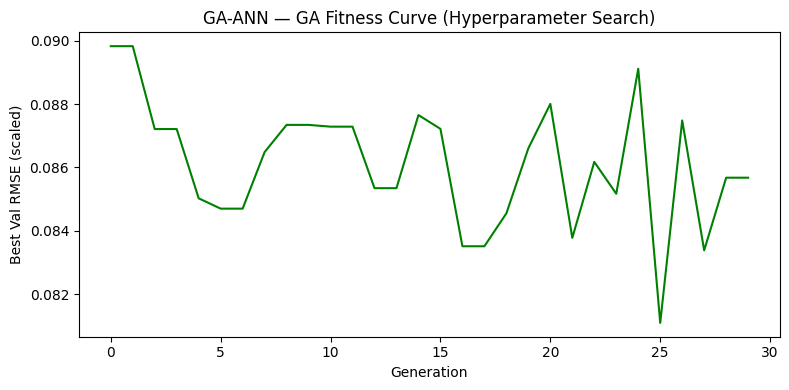

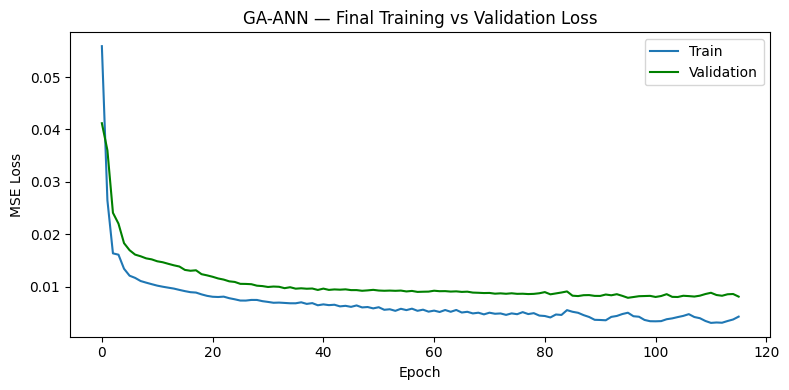

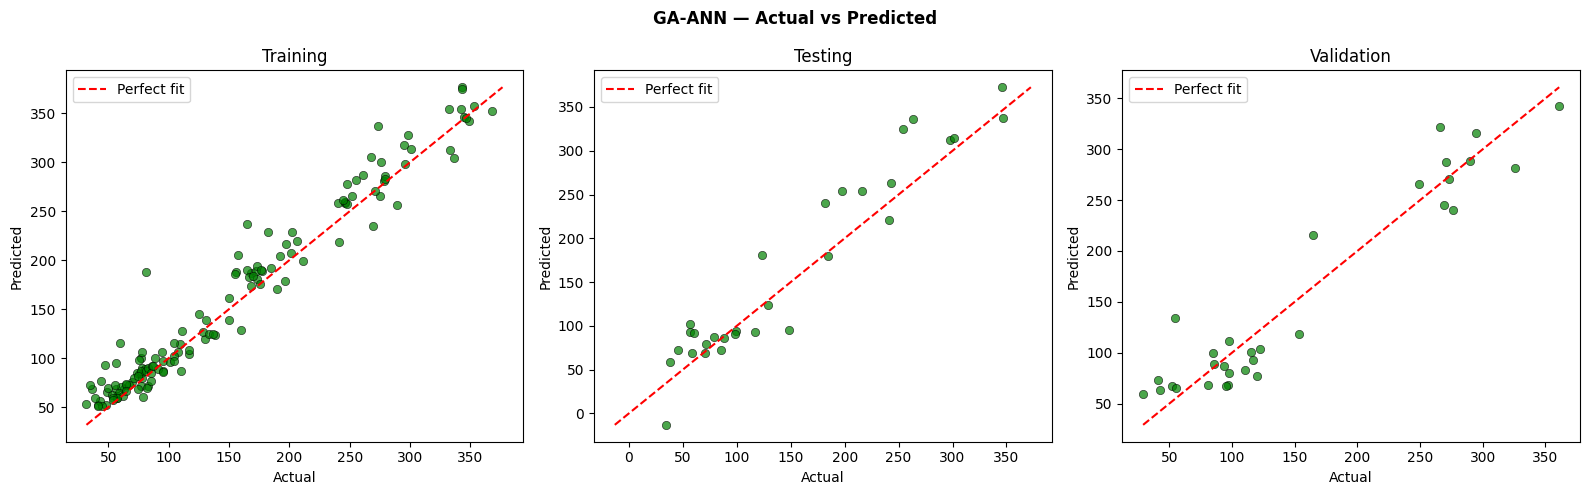

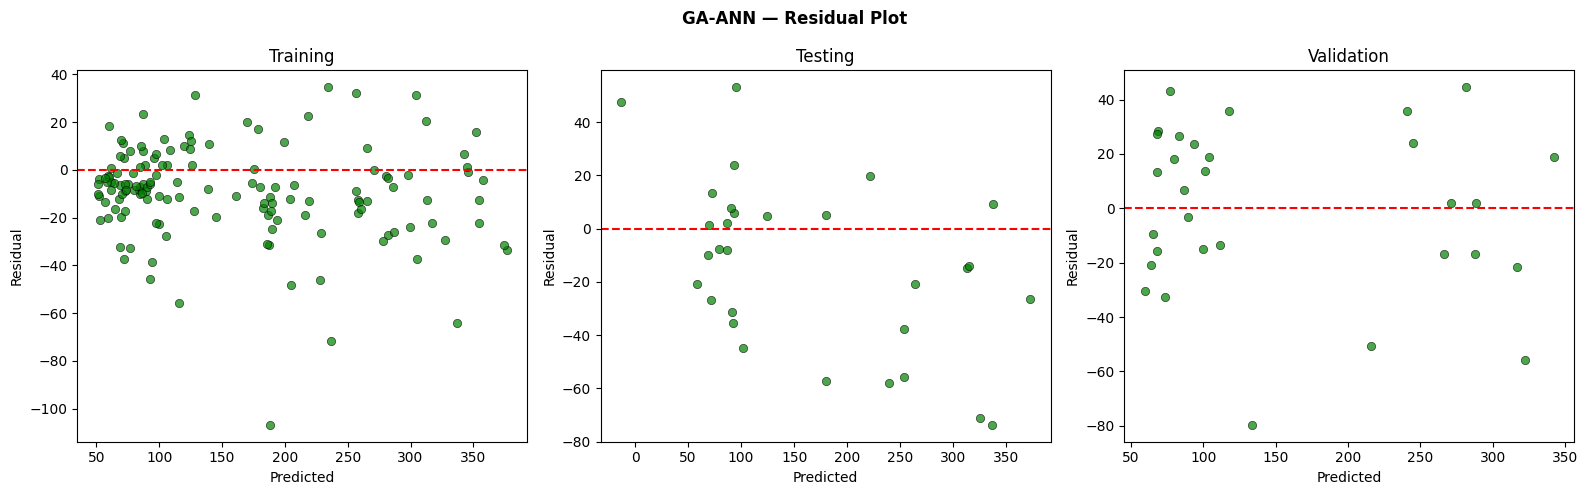

In [ ]:
# ── GA-ANN — Plots ──────────────────────────────────────────────────────

plt.figure(figsize=(8,4))
plt.plot(ga_ann_best_per_gen, color='green')
plt.xlabel('Generation'); plt.ylabel('Best Val RMSE (scaled)')
plt.title('GA-ANN — GA Fitness Curve (Hyperparameter Search)')
plt.tight_layout(); plt.savefig('GA_ANN_fitness_curve.png', dpi=150); plt.show()

plt.figure(figsize=(8,4))
plt.plot(ga_ann_history.history['loss'],     label='Train')
plt.plot(ga_ann_history.history['val_loss'], label='Validation', color='green')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.title('GA-ANN — Final Training vs Validation Loss'); plt.legend()
plt.tight_layout(); plt.savefig('GA_ANN_loss_curve.png', dpi=150); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16,5))
fig.suptitle('GA-ANN — Actual vs Predicted', fontweight='bold')
for ax, (yt, yp, ttl) in zip(axes, [
        (y_true_train, y_pred_train_GAANN, 'Training'),
        (y_true_test,  y_pred_test_GAANN,  'Testing'),
        (y_true_val,   y_pred_val_GAANN,   'Validation')]):
    ax.scatter(yt, yp, alpha=0.7, edgecolors='k', lw=0.5, color='green')
    lo, hi = min(yt.min(), yp.min()), max(yt.max(), yp.max())
    ax.plot([lo,hi],[lo,hi],'r--',lw=1.5,label='Perfect fit')
    ax.set_title(ttl); ax.set_xlabel('Actual'); ax.set_ylabel('Predicted'); ax.legend()
plt.tight_layout(); plt.savefig('GA_ANN_actual_vs_predicted.png', dpi=150); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16,5))
fig.suptitle('GA-ANN — Residual Plot', fontweight='bold')
for ax, (yt, yp, ttl) in zip(axes, [
        (y_true_train, y_pred_train_GAANN, 'Training'),
        (y_true_test,  y_pred_test_GAANN,  'Testing'),
        (y_true_val,   y_pred_val_GAANN,   'Validation')]):
    ax.scatter(yp, yt-yp, alpha=0.7, edgecolors='k', lw=0.5, color='green')
    ax.axhline(0, color='r', ls='--', lw=1.5)
    ax.set_title(ttl); ax.set_xlabel('Predicted'); ax.set_ylabel('Residual')
plt.tight_layout(); plt.savefig('GA_ANN_residuals.png', dpi=150); plt.show()

In [ ]:
# ── PART 7 — Final Model Comparison ────────────────────────────────────

rows = []
for mname, res in [('ANN', ann_results), ('GA', ga_results), ('GA-ANN', ga_ann_results)]:
    for split, metrics in res.items():
        rows.append({'Model': mname, 'Dataset': split, **metrics})

df_summary = pd.DataFrame(rows)
print('Full Performance Summary:')
print(df_summary.to_string(index=False))

Full Performance Summary:
 Model    Dataset      R     R²    RMSE     MAE  MAPE (%)
   ANN   Training 0.9852 0.9642 17.7928 12.6012   11.5030
   ANN    Testing 0.9631 0.8898 31.7592 25.1681   20.0688
   ANN Validation 0.9612 0.9194 27.8104 24.7439   23.6240
    GA   Training 0.9173 0.8379 37.8446 27.4399   23.4540
    GA    Testing 0.9090 0.8147 41.1835 35.5335   40.9089
    GA Validation 0.9006 0.8047 43.3025 36.9897   36.3167
GA-ANN   Training 0.9785 0.9468 21.6848 15.8000   15.4450
GA-ANN    Testing 0.9580 0.8714 34.3110 26.9677   26.5468
GA-ANN Validation 0.9532 0.9075 29.7965 24.6804   26.0348


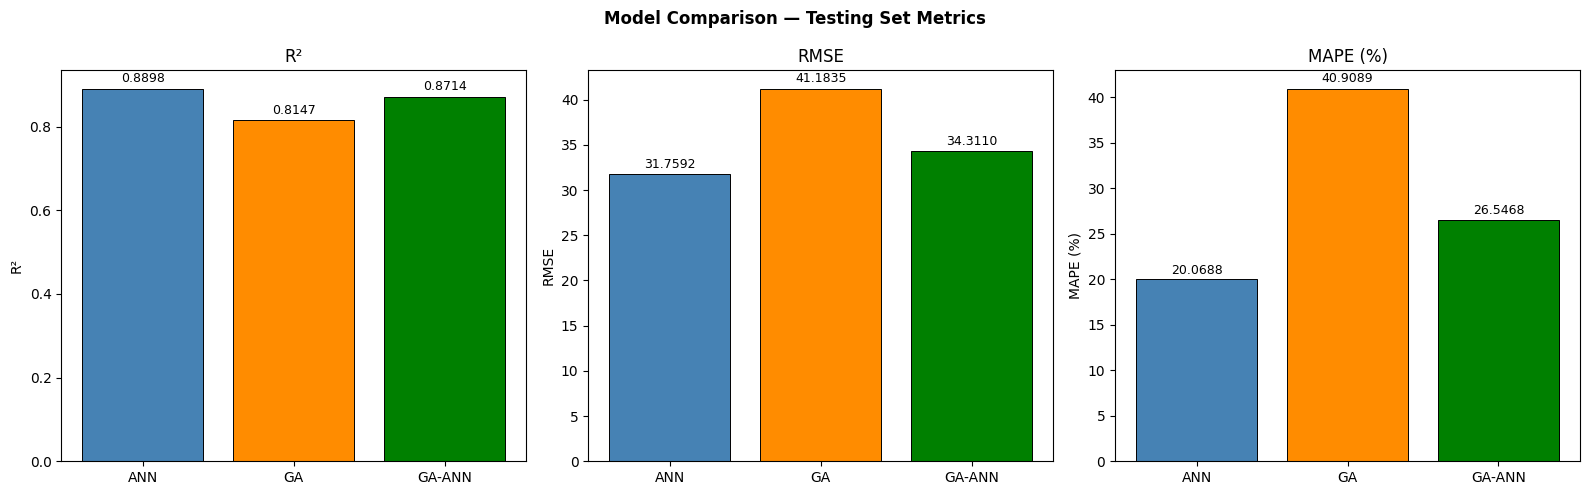


── Diagnostic Report ──
  ✔  [ANN] No significant overfitting (Train R²=0.9642, Test R²=0.8898)
  ✔  [GA] No significant overfitting (Train R²=0.8379, Test R²=0.8147)
  ✔  [GA-ANN] No significant overfitting (Train R²=0.9468, Test R²=0.8714)

  Best by Testing RMSE    : ANN (31.7592)
  Best by Validation RMSE : ANN (27.8104)

  ✅ CONCLUSION: ANN shows best generalisation on both unseen sets.

✅ All models complete. PNG plots saved in working directory.


In [ ]:
# ── Comparison Bar Chart ────────────────────────────────────────────────

model_labels = ['ANN', 'GA', 'GA-ANN']
colors = ['steelblue', 'darkorange', 'green']

fig, axes = plt.subplots(1, 3, figsize=(16,5))
fig.suptitle('Model Comparison — Testing Set Metrics', fontweight='bold')
for ax, metric in zip(axes, ['R²', 'RMSE', 'MAPE (%)']):
    vals = [df_summary.loc[
        (df_summary['Model']==m) & (df_summary['Dataset']=='Testing'), metric
        ].values[0] for m in model_labels]
    bars = ax.bar(model_labels, vals, color=colors, edgecolor='k', lw=0.7)
    ax.set_title(metric); ax.set_ylabel(metric)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()*1.01,
                f'{v:.4f}', ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.savefig('Model_comparison_bar.png', dpi=150); plt.show()

# Overfitting check
print('\n── Diagnostic Report ──')
THRESH = 0.10
for mname in model_labels:
    tr = df_summary.loc[(df_summary['Model']==mname)&(df_summary['Dataset']=='Training'),'R²'].values[0]
    te = df_summary.loc[(df_summary['Model']==mname)&(df_summary['Dataset']=='Testing'),'R²'].values[0]
    gap = tr - te
    if gap > THRESH:
        print(f'  ⚠  OVERFITTING [{mname}]: Train R²={tr:.4f} | Test R²={te:.4f} | gap={gap:.4f}')
    else:
        print(f'  ✔  [{mname}] No significant overfitting (Train R²={tr:.4f}, Test R²={te:.4f})')

# Best model
test_rmse = {m: df_summary.loc[(df_summary['Model']==m)&(df_summary['Dataset']=='Testing'),'RMSE'].values[0] for m in model_labels}
val_rmse  = {m: df_summary.loc[(df_summary['Model']==m)&(df_summary['Dataset']=='Validation'),'RMSE'].values[0] for m in model_labels}
best_t = min(test_rmse, key=test_rmse.get)
best_v = min(val_rmse,  key=val_rmse.get)
print(f'\n  Best by Testing RMSE    : {best_t} ({test_rmse[best_t]:.4f})')
print(f'  Best by Validation RMSE : {best_v} ({val_rmse[best_v]:.4f})')
if best_t == best_v:
    print(f'\n  ✅ CONCLUSION: {best_t} shows best generalisation on both unseen sets.')
else:
    print(f'\n  ⚠  Best Testing ({best_t}) ≠ Best Validation ({best_v}). Review both models.')

print('\n✅ All models complete. PNG plots saved in working directory.')